In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from x5uplift.features import connect, create_baskets, demographics
from x5uplift import plotting as P

pd.set_option("display.width", 140)
P.set_style()

con = connect()
create_baskets(con)

def q(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return con.execute(sql).df()

q("""
SELECT COUNT(*) AS n_baskets, SUM(n_items) AS n_item_rows,
       MIN(reg_points_spent) AS min_reg_spent, MIN(exp_points_spent) AS min_exp_spent
FROM baskets
""")

,n_baskets,n_item_rows,min_reg_spent,min_exp_spent
0,8045229,45786568.0,0.0,0.0


In [2]:
demo = demographics(con)
print(len(demo), "clients")
demo.describe(include="all").T

400162 clients


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
client_id,400162,400162,fffff6ce77,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,398383.0,<NA>,<NA>,<NA>,46.419029,15.875483,14.0,34.0,45.0,59.0,100.0
age_missing,400162.0,NaN,NaN,NaN,0.004446,0.066528,0.0,0.0,0.0,0.0,1.0
gender,400162,3,U,185706,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_since_card_issue,400162.0,NaN,NaN,NaN,432.916539,203.610137,3.0,271.0,487.0,605.0,713.0
redeemed_before_cutoff,400162.0,NaN,NaN,NaN,0.799026,0.400729,0.0,1.0,1.0,1.0,1.0
days_since_first_redeem,319740.0,<NA>,<NA>,<NA>,312.970895,188.142099,0.0,134.0,330.0,465.0,706.0
days_issue_to_redeem,319740.0,<NA>,<NA>,<NA>,161.509817,134.750851,0.0,57.0,122.0,229.0,703.0


In [3]:
from x5uplift.config import CUTOFF

q(f"""
SELECT
    COUNT(*) FILTER (WHERE first_redeem_date < first_issue_date)                       AS n_redeem_before_issue,
    COUNT(*) FILTER (WHERE first_redeem_date < first_issue_date
                       AND first_redeem_date <= TIMESTAMP '{CUTOFF}')                   AS n_before_issue_and_cutoff,
    QUANTILE_CONT(DATE_DIFF('second', first_redeem_date, first_issue_date) / 86400.0, [0.5, 0.9])
        FILTER (WHERE first_redeem_date < first_issue_date)                            AS gap_days_q50_q90
FROM clients
""")

,n_redeem_before_issue,n_before_issue_and_cutoff,gap_days_q50_q90
0,536,536,"[0.00014467592592592592, 0.00037037037037037035]"


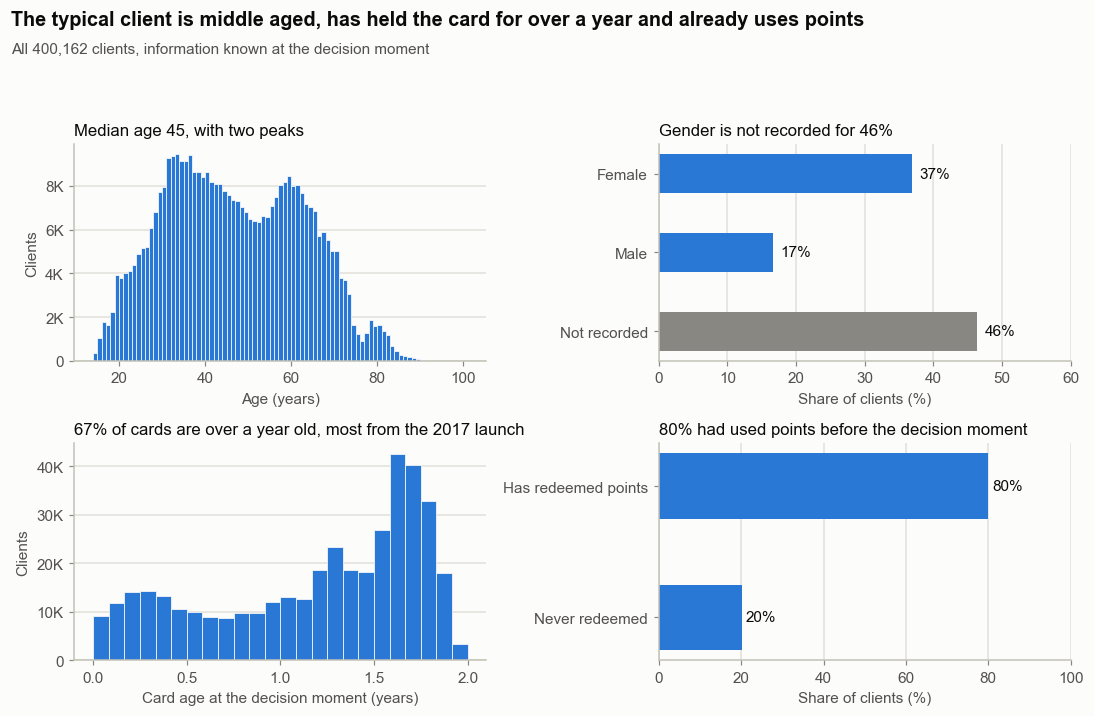

In [4]:
n_clients = len(demo)
gender_share = demo["gender"].value_counts(normalize=True).reindex(["F", "M", "U"]) * 100
gender_labels = {"F": "Female", "M": "Male", "U": "Not recorded"}
redeem_share = demo["redeemed_before_cutoff"].mean() * 100
card_years = demo["days_since_card_issue"] / 365.25

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
(ax_age, ax_gender), (ax_card, ax_points) = axes

# Age
ax_age.hist(demo["age"].dropna(), bins=np.arange(14, 102, 1), color=P.BLUE,
            edgecolor=P.SURFACE, linewidth=0.5)
ax_age.set_xlabel("Age (years)")
ax_age.set_ylabel("Clients")
ax_age.set_title(f"Median age {demo['age'].median():.0f}, with two peaks", loc="left", fontsize=11)

# Gender (unknown shown in grey)
names = [gender_labels[g] for g in gender_share.index]
colors = [P.MUTED if g == "U" else P.BLUE for g in gender_share.index]
ax_gender.barh(names, gender_share.values, color=colors, height=0.5)
for y, v in enumerate(gender_share.values):
    ax_gender.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=10, color=P.INK)
ax_gender.invert_yaxis()
ax_gender.set_xlim(0, 60)
ax_gender.set_xlabel("Share of clients (%)")
ax_gender.grid(axis="y", visible=False)
ax_gender.grid(axis="x", visible=True)
ax_gender.set_title(f"Gender is not recorded for {gender_share['U']:.0f}%", loc="left", fontsize=11)

# Card age
ax_card.hist(card_years, bins=np.arange(0, 2.01, 1 / 12), color=P.BLUE,
             edgecolor=P.SURFACE, linewidth=0.5)
ax_card.set_xlabel("Card age at the decision moment (years)")
ax_card.set_ylabel("Clients")
ax_card.set_title(f"{(card_years > 1).mean() * 100:.0f}% of cards are over a year old, most from the 2017 launch",
                  loc="left", fontsize=11)

# Points use
ax_points.barh(["Has redeemed points", "Never redeemed"], [redeem_share, 100 - redeem_share],
               color=P.BLUE, height=0.5)
for y, v in enumerate([redeem_share, 100 - redeem_share]):
    ax_points.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=10, color=P.INK)
ax_points.invert_yaxis()
ax_points.set_xlim(0, 100)
ax_points.set_xlabel("Share of clients (%)")
ax_points.grid(axis="y", visible=False)
ax_points.grid(axis="x", visible=True)
ax_points.set_title(f"{redeem_share:.0f}% had used points before the decision moment", loc="left", fontsize=11)

for ax in (ax_age, ax_card):
    ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}K" if v >= 1000 else f"{v:.0f}")

fig.suptitle("The typical client is middle aged, has held the card for over a year and already uses points",
             x=0.01, y=0.995, ha="left", va="top", fontsize=13, fontweight="bold")
fig.text(0.01, 0.95, f"All {n_clients:,} clients, information known at the decision moment",
         ha="left", va="top", fontsize=10, color=P.INK_2)
fig.tight_layout(rect=(0, 0, 1, 0.91))
P.save(fig, "02_client_profile")
plt.show()

In [5]:
from x5uplift.features import build_features

features, feature_groups = build_features(con)
print(features.shape)
print({group: len(cols) for group, cols in feature_groups.items()})

share_cols = [c for c in features.columns if c.startswith("share_") or c == "top_store_share"]
checks = pd.Series({
    "rows (expect 400,162)": len(features),
    "ids unique": features["client_id"].is_unique,
    "baskets (expect 8,045,229)": int(features["n_baskets"].sum()),
    "spend equals basket table": bool(np.isclose(features["total_spend"].sum(),
                                                 q("SELECT SUM(basket_sum) AS s FROM baskets")["s"][0])),
    "min days since last purchase (expect >= 0)": features["days_since_last_purchase"].min(),
    "max days since first purchase (expect about 117)": features["days_since_first_purchase"].max(),
    "share columns inside [0, 1]": all(features[c].dropna().between(0, 1).all() for c in share_cols),
    "missing overdue_ratio (clients with one basket)": int(features["overdue_ratio"].isna().sum()),
})
checks

(400162, 37)
{'demographics': 7, 'rfm_trend': 16, 'points': 6, 'basket_content': 3, 'stores': 2, 'time_habits': 2}


rows (expect 400,162)                                   400162
ids unique                                                True
baskets (expect 8,045,229)                             8045229
spend equals basket table                                 True
min days since last purchase (expect >= 0)                 0.0
max days since first purchase (expect about 117)    117.109375
share columns inside [0, 1]                               True
missing overdue_ratio (clients with one basket)           7707
dtype: object

In [6]:
from x5uplift.features import CUT

cat_spend = q(f"""
SELECT
    p.level_1,
    p.level_2,
    SUM(u.trn_sum_from_iss)      AS spend,
    COUNT(DISTINCT u.client_id)  AS n_clients
FROM purchases AS u
JOIN products AS p USING (product_id)
WHERE u.transaction_datetime <= {CUT}
GROUP BY 1, 2
""")

total_spend = cat_spend["spend"].sum()
n_all_clients = len(features)

by_l1 = cat_spend.groupby("level_1", dropna=False)["spend"].sum().div(total_spend).mul(100).round(1)

by_l2 = cat_spend.sort_values("spend", ascending=False).reset_index(drop=True)
by_l2["spend_share"] = by_l2["spend"] / total_spend * 100
by_l2["cum_spend_share"] = by_l2["spend_share"].cumsum()
by_l2["client_share"] = by_l2["n_clients"] / n_all_clients * 100

display(by_l1)
display(by_l2[["level_1", "spend_share", "cum_spend_share", "client_share"]].round(1))

level_1
c3d3a8e8c6    46.0
e344ab2e71    52.1
ec62ce61e3     1.9
NaN            0.0
Name: spend, dtype: float64

,level_1,spend_share,cum_spend_share,client_share
0,c3d3a8e8c6,16.0,16.0,94.6
1,e344ab2e71,14.4,30.4,96.1
2,c3d3a8e8c6,12.8,43.2,92.8
3,e344ab2e71,10.2,53.4,92.4
4,e344ab2e71,6.7,60.1,42.9
5,e344ab2e71,6.5,66.5,77.4
6,e344ab2e71,6.1,72.6,91.5
7,c3d3a8e8c6,5.3,77.9,65.6
8,c3d3a8e8c6,4.1,81.9,49.7
9,e344ab2e71,3.8,85.7,87.2
